# Contact-map cell embedding with FastHigashi

FastHigashi (Zhang et al. 2022, *Cell Systems*) embeds single-cell Hi-C maps by a tensor decomposition of
all cells' contact maps, chromosome by chromosome.  This tutorial runs it on sci-Hi-C of two human cell lines,
in three calls:

- `uchrom.datasets.load` gives the dataset as a `ChromData`: the cells, their published cell types and their
  contact maps (linked, one `.scool`);
- `uc.tl.embed_higashi` runs FastHigashi on those maps and stores the embedding in `cd.cellm["higashi"]`;
- `uchrom.emb.score_embedding` scores it against the cell types (ARI / NMI, kNN purity); `uc.tl.embed_cells`
  and `uc.tl.cluster_cells` give t-SNE / UMAP and Leiden clusters.

- **Data**: Kim et al. 2020 (*PLOS Comput. Biol.* 16:e1008173) sci-Hi-C of an H1 ES cell (H1Esc) and foreskin
  fibroblast (HFF) mix: 1,931 cells at 500 kb, hg19, with cell-type labels.  The first `ds.load` downloads the
  contact matrices (128 MB) and the labels once from the Noble lab and builds the `ChromData` in the data
  directory (~20 s); afterwards it is read from there.
- **Runtime**: 3–5 min on a laptop CPU (FastHigashi itself takes 1–3 min), for 150 cells of each type picked
  at random.
- **Requirements**: FastHigashi is an optional dependency and is not on PyPI.  Install it from GitHub in an
  environment with NumPy < 2, because FastHigashi 0.1.1a0 calls `np.array(..., copy=False)`:

  ```
  pip install "numpy<2" opt_einsum tqdm psutil
  pip install git+https://github.com/ma-compbio/Fast-Higashi
  ```

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import uchrom as uc
import uchrom.datasets as ds
import uchrom.emb as emb

plt.rcParams["figure.dpi"] = 90
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by umap-learn

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
T0 = time.time()

## 1. The data as a `ChromData`

`ds.load("kim2020_scihic")` returns the cells with their cell type and number of contacts.  The data have
contacts but no 3-D coordinates, so the `ChromData` has cells and no spots.  The contact maps stay in their own
file, a `.scool` with one 500 kb map per cell, linked under the key `per_cell` (`cd.uns["linked_scool"]`).
The loader built it from the original per-cell matrices, checking that every bin falls inside its
chromosome under the hg19 numbering.

In [2]:
cd = ds.load("kim2020_scihic")
print(cd)
print(cd.cells["cell_type"].value_counts().to_dict(), "| median contacts per cell:", int(cd.cells["n_contacts"].median()))
cd.uns["linked_scool"]["per_cell"]

ChromData: n_spots=0, n_traces=0, n_cells=1931, n_bins=0
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['cell_type', 'n_contacts'] (1931 cells)
  uns:     ['genome_assembly', 'source', 'linked_scool', 'dataset']
{'HFF': 1181, 'H1Esc': 750} | median contacts per cell: 4102


{'path': 'kim2020_scihic_500kb.scool',
 'format': 'scool',
 'cell_name': 'cell_id',
 'genome_assembly': 'hg19',
 'bin_size': 500000,
 'coordinate_status': 'contacts, not xyz coordinates'}

Each cell's map is a cooler in the `.scool`; `load_linked_scool` opens one (also from an atlas store, where
the maps are embedded instead of linked):

In [3]:
one = cd.load_linked_scool(key="per_cell", cell=cd.cells.index[0])
print(f"{cd.cells.index[0]}: {one.binsize // 1000} kb bins, {one.info['sum']:,} contacts in {one.info['nnz']:,} pixels")
one.pixels(join=True)[:3]

human_10019_GATGCAGG-GTAGACAC: 500 kb bins, 10,019 contacts in 8,533 pixels


,chrom1,start1,end1,chrom2,start2,end2,count
0,chr1,1000000,1500000,chr9,140000000,140500000,1
1,chr1,1000000,1500000,chr16,15500000,16000000,2
2,chr1,1500000,2000000,chr1,1500000,2000000,1


## 2. Pick the cells

We pick 150 H1Esc and 150 HFF cells at random (seed 0).  FastHigashi needs population diversity; more cells
give a better embedding but take longer.  `get_cells` keeps the chosen cells — with their metadata and the
link to their maps — in a new `ChromData`.

In [4]:
pick = pd.concat([cd.cells[cd.cells["cell_type"] == t].sample(150, random_state=0) for t in ("H1Esc", "HFF")]).index
cd = cd.get_cells(pick)
print(cd.n_cells, "cells; median contacts:", cd.cells.groupby("cell_type")["n_contacts"].median().to_dict())

300 cells; median contacts: {'H1Esc': 7570.0, 'HFF': 2794.0}


## 3. Run FastHigashi

`uc.tl.embed_higashi` (= `uchrom.emb.embed_higashi`) reads the linked maps of the cells, writes FastHigashi's
inputs (one contact table per cell, label info, chromosome sizes, `config.JSON`) under `work_dir`, runs
FastHigashi's four steps there and puts the embedding on the cells axis.  Its defaults are those of this
tutorial:

- smoothing (`conv`), random walk with restart (`rwr`) and column normalisation (`col`) of the very sparse
  maps; rank 64; chromosomes 1–22 and X;
- the stored variant is `embed_l2_norm_correct_coverage_fh`: the embedding after FastHigashi regresses out
  each cell's coverage, L2-normalised.  The HFF cells here have about 3× fewer contacts than the H1Esc cells,
  so coverage alone would separate the two types in an uncorrected embedding.  `keep_variants=True` also
  stores the other variants FastHigashi computes (`cd.cellm["higashi.<variant>"]`), to compare them below;
- FastHigashi's initialisation and final SVD are random: `seed` makes a run reproducible;
- its progress output goes to `work_dir/fasthigashi.log`; on machines without CUDA (Apple Silicon)
  `pin_memory` is made a no-op for the run.

In [5]:
t = time.time()
uc.tl.embed_higashi(cd, rank=64, seed=0, keep_variants=True, work_dir=OUT / "higashi_kim2020")
print(f"FastHigashi: {time.time() - t:.0f} s; cd.cellm['higashi'] {cd.cellm['higashi'].shape}")
{k: v for k, v in cd.uns["higashi"].items() if k not in ("chroms", "variants")}

FastHigashi: 92 s; cd.cellm['higashi'] (300, 64)


{'method': 'fasthigashi',
 'contacts': 'per_cell',
 'rank': 64,
 'variant': 'embed_l2_norm_correct_coverage_fh',
 'conv': True,
 'rwr': True,
 'col': True,
 'off_diag': 100,
 'filter': False,
 'seed': 0,
 'resolution': 500000,
 'n_cells': 300,
 'n_pass_qc': 122,
 'work_dir': '_out/higashi_kim2020',
 'log': '_out/higashi_kim2020/fasthigashi.log'}

## 4. Score the embedding against the cell types

FastHigashi flags cells by quality: a cell passes when enough bins of every chromosome have contacts
(`cd.cells["higashi_qc"]`).  `emb.score_embedding` clusters an embedding with k-means (as many clusters as
cell types) and compares the clusters with the labels by ARI and NMI (0 = chance, 1 = perfect), measures the
kNN purity (the share of each cell's 10 nearest neighbours of its own type) and, with `depth=`, how much the
first dimension follows the number of contacts.  We score all cells and the cells that pass QC, and the
other variants.

In [6]:
print("FastHigashi QC:", pd.crosstab(cd.cells["cell_type"], cd.cells["higashi_qc"]).to_dict("index"))
scores = {"stored, all cells": emb.score_embedding(cd, "higashi", "cell_type", depth="n_contacts"),
          "stored, QC pass": emb.score_embedding(cd, "higashi", "cell_type", cells="higashi_qc", depth="n_contacts")}
for key in sorted(k for k in cd.cellm if k.startswith("higashi.")):
    scores[f"{key.removeprefix('higashi.')}, all cells"] = emb.score_embedding(cd, key, "cell_type", depth="n_contacts")
pd.DataFrame(scores).T.round(3)

FastHigashi QC: {'H1Esc': {'pass': 90, 'fail': 60}, 'HFF': {'pass': 32, 'fail': 118}}


,n_cells,ARI,NMI,kNN purity,|r| dim 1 ~ log depth
"stored, all cells",300.0,0.479,0.408,0.799,0.310
"stored, QC pass",122.0,1.000,1.000,0.998,0.329
"embed_all, all cells",300.0,0.004,0.016,0.847,0.716
"embed_correct_coverage_fh, all cells",300.0,-0.000,0.002,0.778,0.045
"embed_l2_norm, all cells",300.0,0.228,0.228,0.825,0.760
"embed_raw, all cells",300.0,0.004,0.016,0.847,0.647


On the cells that pass QC, k-means splits H1Esc from HFF perfectly (ARI 1, kNN purity 1.0).  The cells that
fail are mostly HFF cells with few contacts (118 of 150 HFF, 60 of 150 H1Esc).  For them coverage dominates the
uncorrected variants: their first dimension follows the number of contacts (|r| 0.65–0.76) and over all cells
they do not separate the types (`embed_raw`, `embed_all`: ARI ≈ 0).  The stored variant regresses out
coverage and then L2-normalises: |r| drops to 0.31 and the all-cell ARI is 0.48, twice that of
`embed_l2_norm` (0.23), but the low-coverage cells still blur the picture; the corrected variant without
normalisation removes coverage (|r| 0.05) and the types with it (ARI 0).  More cells, or a minimum number of
contacts per cell, help.  The all-cell numbers also depend on the random initialisation: without a seed, the
ARI of the stored variant ranged from 0.42 to 0.51 in our runs, while the QC-pass ARI stayed at 1.

## 5. t-SNE / UMAP and Leiden clusters

The FastHigashi embedding is a cells × 64 matrix, so `uc.tl.embed_cells` takes it like any other features:
`source="higashi"` is shown as the Hi-C modality, and `normalization="none"` uses the values as they are.  This
gives `higashi_pca`, `higashi_tsne` and `higashi_umap`, recorded in `cd.uns["embeddings"]` for the web browser.
`uc.tl.cluster_cells` then computes Leiden clusters, and `emb.cluster_agreement` compares them with the cell
types.

3 Leiden clusters: {'ARI': 0.187, 'NMI': 0.304}


cell_type      H1Esc       HFF     
higashi_qc      pass fail pass fail
leiden_higashi                     
0                 21   55   12  117
1                 69    5    0    1
2                  0    0   20    0

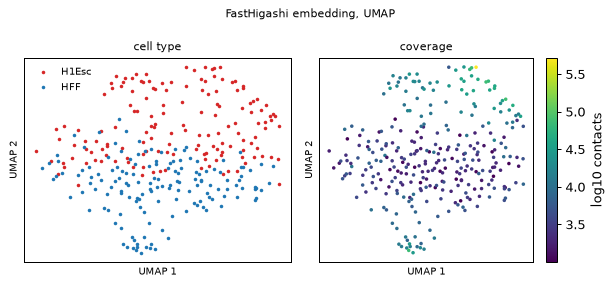

In [7]:
uc.tl.embed_cells(cd, source="higashi", matrix=cd.cellm["higashi"], normalization="none", n_pcs=20,
                  features="FastHigashi (rank 64, conv + rwr + col), coverage-corrected, L2-normalised")
leiden = uc.tl.cluster_cells(cd, use="higashi_pca", resolution=0.5, key_added="leiden_higashi")
print(f"{leiden.nunique()} Leiden clusters:", {k: round(v, 3) for k, v in emb.cluster_agreement(leiden, cd.cells["cell_type"]).items()})
display(pd.crosstab(leiden, [cd.cells["cell_type"], cd.cells["higashi_qc"]]).rename_axis(index="leiden_higashi"))

y, xy = cd.cells["cell_type"].to_numpy(), cd.cellm["higashi_umap"]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for t, color in [("H1Esc", "tab:red"), ("HFF", "tab:blue")]:
    m = y == t
    axes[0].scatter(xy[m, 0], xy[m, 1], s=8, lw=0, color=color, label=t)
axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("cell type", fontsize=9)
sc = axes[1].scatter(xy[:, 0], xy[:, 1], s=8, lw=0, c=np.log10(cd.cells["n_contacts"]), cmap="viridis")
fig.colorbar(sc, ax=axes[1], label="log10 contacts"); axes[1].set_title("coverage", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP 1", fontsize=8); ax.set_ylabel("UMAP 2", fontsize=8)
fig.suptitle("FastHigashi embedding, UMAP", fontsize=9)
fig.tight_layout()

Leiden gives the same picture as k-means.  Most cells that pass QC fall into a cluster of their own type —
69 of the 90 H1Esc in one, 20 of the 32 HFF in another — while the low-coverage cells of both types form a third,
mixed cluster.  The UMAP shows this too: the cells with many contacts separate by type, and those with few
contacts mix.

## 6. Store the result

The embedding and its provenance stay with the cells: `cd.cellm["higashi"]` holds the embedding,
`cd.cells["higashi_qc"]` the QC flags, `cd.uns["higashi"]` the settings, and `cd.results` records the call
(function, parameters, version).  FastHigashi's imputed per-cell maps can be large, so they stay in its work
directory; `ChromData` keeps no per-cell pairwise matrices.

In [8]:
path = OUT / "kim2020_higashi.chromdata.zarr"
cd.write(path)
back = uc.ChromData.read(path)
print(path, "| cellm:", sorted(back.cellm)[:6], "...")
print("equal:", np.allclose(back.cellm["higashi"], cd.cellm["higashi"]), "| record:", back.results.record("higashi").function)
print(f"total runtime {time.time() - T0:.0f} s")

_out/kim2020_higashi.chromdata.zarr | cellm: ['higashi', 'higashi.embed_all', 'higashi.embed_correct_coverage_fh', 'higashi.embed_l2_norm', 'higashi.embed_raw', 'higashi_pca'] ...
equal: True | record: uchrom.emb.embed_higashi
total runtime 99 s


## Next steps

- `cell_embeddings.ipynb`: RNA, ATAC, contact-map (scHiCluster) and IF embeddings of the same cells, Leiden
  clusters, marker features, and how the web browser reads `cd.uns["embeddings"]`.
- Atlas datasets carry their per-cell maps embedded: `uc.tl.embed_higashi(ds.load("hires_brain"))` works on
  them the same way (the cells' maps are exported once, chromosome by chromosome, over HTTP).
- To embed all 1,931 cells, skip `get_cells`.  This takes longer on a CPU; FastHigashi uses a CUDA GPU when one
  is available.